# 1. Imports


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 2. Path config


In [3]:
ROOT = Path.cwd().parent.parent.parent
DATA_DIR = ROOT / "data"
print(ROOT)
print(DATA_DIR)

/home/samuel/projects/machine-learning-from-scratch
/home/samuel/projects/machine-learning-from-scratch/data


# 3. Load data


In [4]:
df = pd.read_csv(DATA_DIR / "API_NY.GDP.PCAP.CD_DS2_en_csv_v2_1529.csv")
# gdp_df.rename(columns={"Entity": "country_name", "Year": "year", "GDP per capita": "GDP_per_capita"}, inplace=True)

In [5]:
# Remove unnecessary columns
df = df.drop(columns=["Unnamed: 70"], errors="ignore")

# Remove metadata columns that are not needed
df = df.drop(columns=["Indicator Name", "Indicator Code"])

# Rename columns
df = df.rename(columns={"Country Name": "country", "Country Code": "country_code"})

# Remove rows without country information
df = df.dropna(subset=["country", "country_code"])

# Remove duplicate countries
df = df.drop_duplicates(subset=["country_code"])

In [6]:
df = df.melt(
    id_vars=["country", "country_code"], var_name="year", value_name="gdp_per_capita"
)

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["gdp_per_capita"] = pd.to_numeric(df["gdp_per_capita"], errors="coerce")

df = df.dropna(subset=["year", "gdp_per_capita"])

df["year"] = df["year"].astype(int)

df = df.sort_values(["country", "year"]).reset_index(drop=True)

In [7]:
df.head()

,country,country_code,year,gdp_per_capita
0,Afghanistan,AFG,2000,174.930991
1,Afghanistan,AFG,2001,138.706822
2,Afghanistan,AFG,2002,178.954088
3,Afghanistan,AFG,2003,198.871116
4,Afghanistan,AFG,2004,221.763654


# 4. Data exploration by country


In [8]:
def df_filtered_by_country(df, country):
    return df[df["country"] == country]

In [9]:
df_brazil = df_filtered_by_country(df, "Brazil")
df_portugal = df_filtered_by_country(df, "Portugal")

df_brazil.head()

,country,country_code,year,gdp_per_capita
1591,Brazil,BRA,1960,235.266010
1592,Brazil,BRA,1961,231.564063
1593,Brazil,BRA,1962,250.200573
1594,Brazil,BRA,1963,294.169619
1595,Brazil,BRA,1964,257.259727


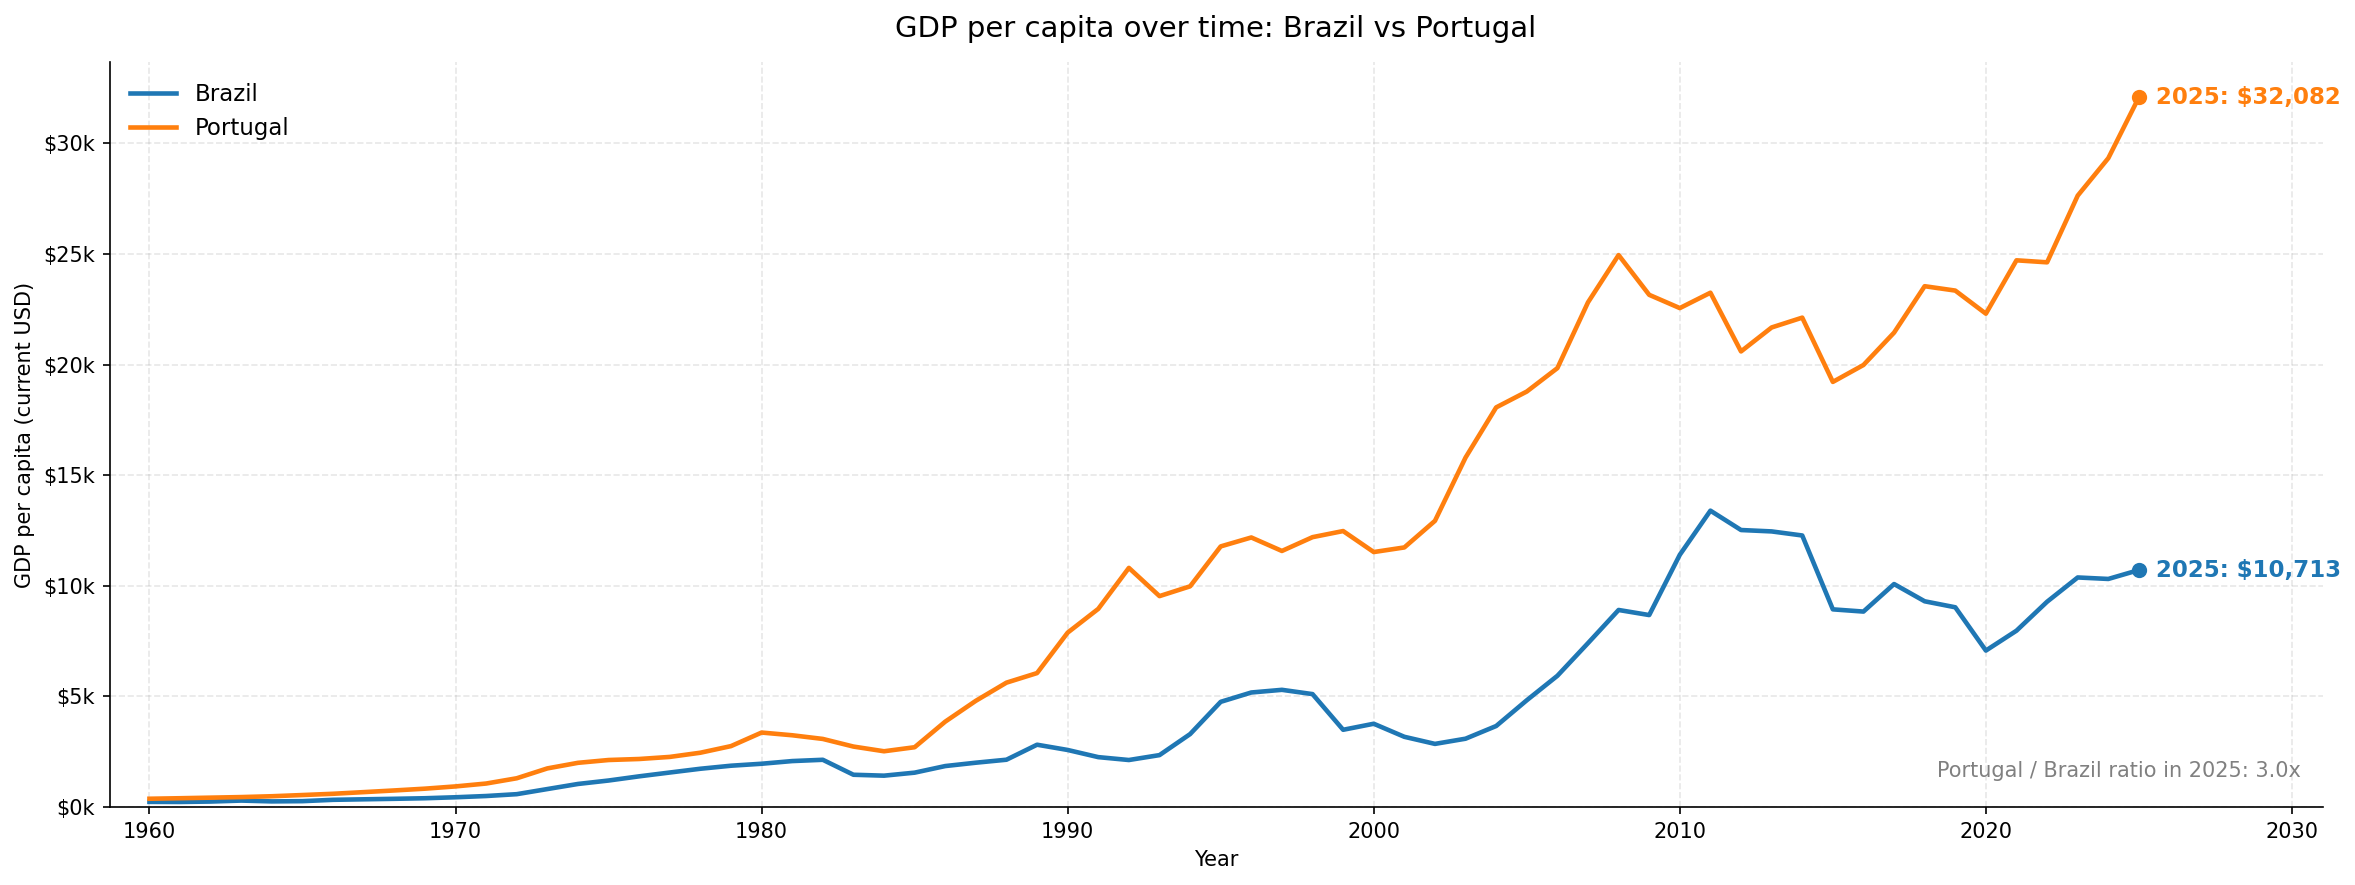

In [45]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


def plot_gdp_comparison(
    df_a, df_b, label_a="Brazil", label_b="Portugal", save_path=None
):
    colors = {label_a: "#1f77b4", label_b: "#ff7f0e"}

    fig, ax = plt.subplots(figsize=(16, 6), dpi=150)

    for df, label in [(df_a, label_a), (df_b, label_b)]:
        ax.plot(
            df["year"],
            df["gdp_per_capita"],
            label=label,
            color=colors[label],
            linewidth=2.2,
        )
        # Marker + annotation at the last data point
        x_last = df["year"].iloc[-1]
        y_last = df["gdp_per_capita"].iloc[-1]
        ax.scatter(x_last, y_last, color=colors[label], s=40, zorder=3)
        ax.annotate(
            f"{x_last}: ${y_last:,.0f}",
            xy=(x_last, y_last),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            fontsize=11,
            fontweight="bold",
            color=colors[label],
        )

    # Ratio between the two countries in the latest year
    ratio = df_b["gdp_per_capita"].iloc[-1] / df_a["gdp_per_capita"].iloc[-1]
    ax.text(
        0.99,
        0.04,
        f"{label_b} / {label_a} ratio in {df_a['year'].iloc[-1]}: {ratio:.1f}x",
        transform=ax.transAxes,
        ha="right",
        fontsize=10,
        color="gray",
    )

    # Axes formatting
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k"))
    ax.set_xlabel("Year")
    ax.set_ylabel("GDP per capita (current USD)")
    ax.set_title("GDP per capita over time: Brazil vs Portugal", fontsize=14, pad=12)

    ax.set_ylim(bottom=0)
    ax.margins(x=0.02)
    ax.set_xlim(right=df_a["year"].max() + 6)  # room for end labels

    ax.grid(True, alpha=0.3, linestyle="--")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=11)

    fig.tight_layout()

    if save_path is not None:
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", facecolor="white")

    return fig, ax


save_path = (
    ROOT / "outputs_results/03_linear_regression_timeseries_forecast/gdp_comparison.png"
)
fig, ax = plot_gdp_comparison(df_brazil, df_portugal, save_path=save_path)
plt.show()

In [21]:
from sklearn.linear_model import LinearRegression

# --- Step 1 again: split in time, never at random ---
brasil_train = df_brazil[df_brazil["year"] <= 2025]
portugal_train = df_portugal[df_portugal["year"] <= 2025]

# --- Step 4: estimate on the TRAINING set only ---
brasil_tslm = LinearRegression().fit(
    brasil_train[["year"]], brasil_train["gdp_per_capita"]
)
portugal_tslm = LinearRegression().fit(
    portugal_train[["year"]], portugal_train["gdp_per_capita"]
)

In [24]:
future_years = np.arange(2026, 2029).reshape(-1, 1)
future_predictions_brazil = brasil_tslm.predict(future_years)
future_predictions_portugal = portugal_tslm.predict(future_years)

print("Future predictions (Brazil):")
for year, prediction in zip(future_years.flatten(), future_predictions_brazil):
    print(f"Year: {year}, Predicted GDP per capita (Brazil): {prediction:.2f}")

print()
print("Future predictions (Portugal):")
for year, prediction in zip(future_years.flatten(), future_predictions_portugal):
    print(f"Year: {year}, Predicted GDP per capita (Portugal): {prediction:.2f}")

Future predictions (Brazil):
Year: 2026, Predicted GDP per capita (Brazil): 10483.85
Year: 2027, Predicted GDP per capita (Brazil): 10667.31
Year: 2028, Predicted GDP per capita (Brazil): 10850.78

Future predictions (Portugal):
Year: 2026, Predicted GDP per capita (Portugal): 27015.66
Year: 2027, Predicted GDP per capita (Portugal): 27492.95
Year: 2028, Predicted GDP per capita (Portugal): 27970.24


/home/samuel/projects/machine-learning-from-scratch/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/home/samuel/projects/machine-learning-from-scratch/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


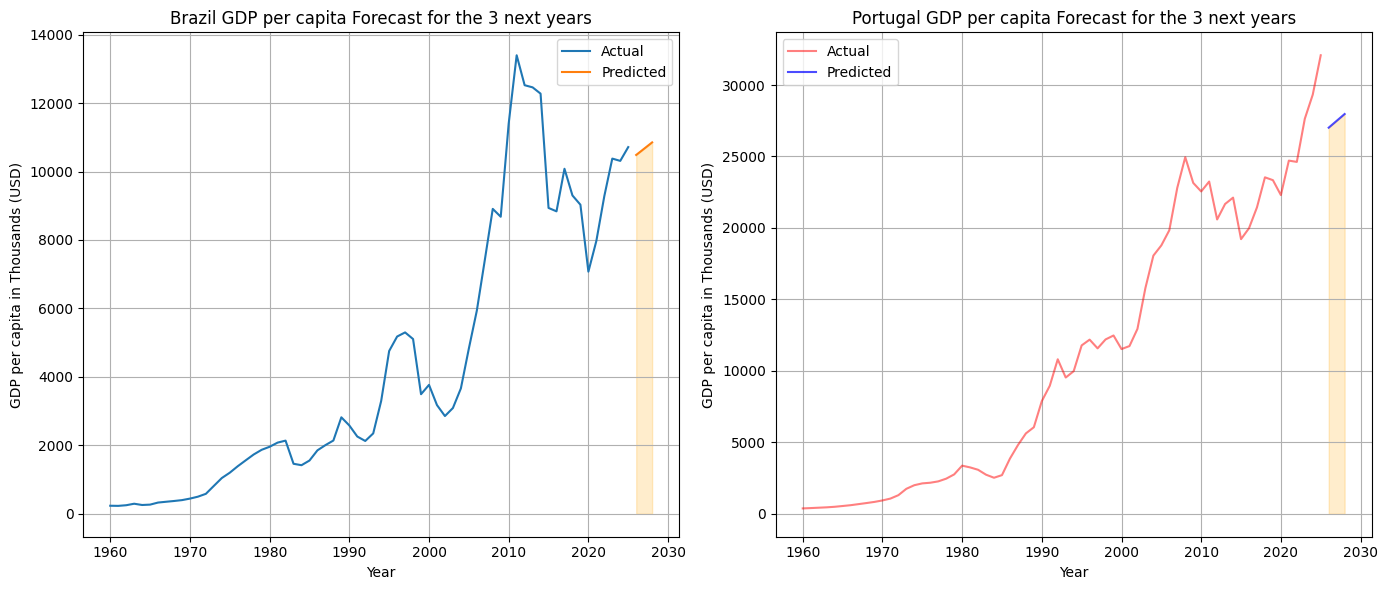

In [ ]:
# Visualize future predictions
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), dpi=100)
ax[0].plot(df_brazil["year"], df_brazil["gdp_per_capita"], label="Actual")
ax[0].plot(future_years, future_predictions_brazil, label="Predicted", linestyle="-")
ax[0].fill_between(
    future_years.flatten(), future_predictions_brazil, alpha=0.2, color="orange"
)
ax[0].set_xlabel("Year")
ax[0].set_ylabel("GDP per capita in Thousands (USD)")
ax[0].set_title(
    f"Brazil GDP per capita Forecast for the {len(future_years)} next years"
)
ax[0].grid(True)
ax[0].legend()

ax[1].plot(
    df_portugal["year"],
    df_portugal["gdp_per_capita"],
    label="Actual",
    color="red",
    alpha=0.5,
)
ax[1].plot(
    future_years,
    future_predictions_portugal,
    label="Predicted",
    linestyle="-",
    color="blue",
    alpha=0.7,
)
ax[1].fill_between(
    future_years.flatten(), future_predictions_portugal, alpha=0.2, color="orange"
)
ax[1].set_xlabel("Year")
ax[1].set_ylabel("GDP per capita in Thousands (USD)")
ax[1].set_title(
    f"Portugal GDP per capita Forecast for the {len(future_years)} next years"
)
ax[1].grid(True)
ax[1].legend()

save_path = "gdp_forecast.png"
plt.savefig(save_path)
plt.tight_layout()
plt.show()

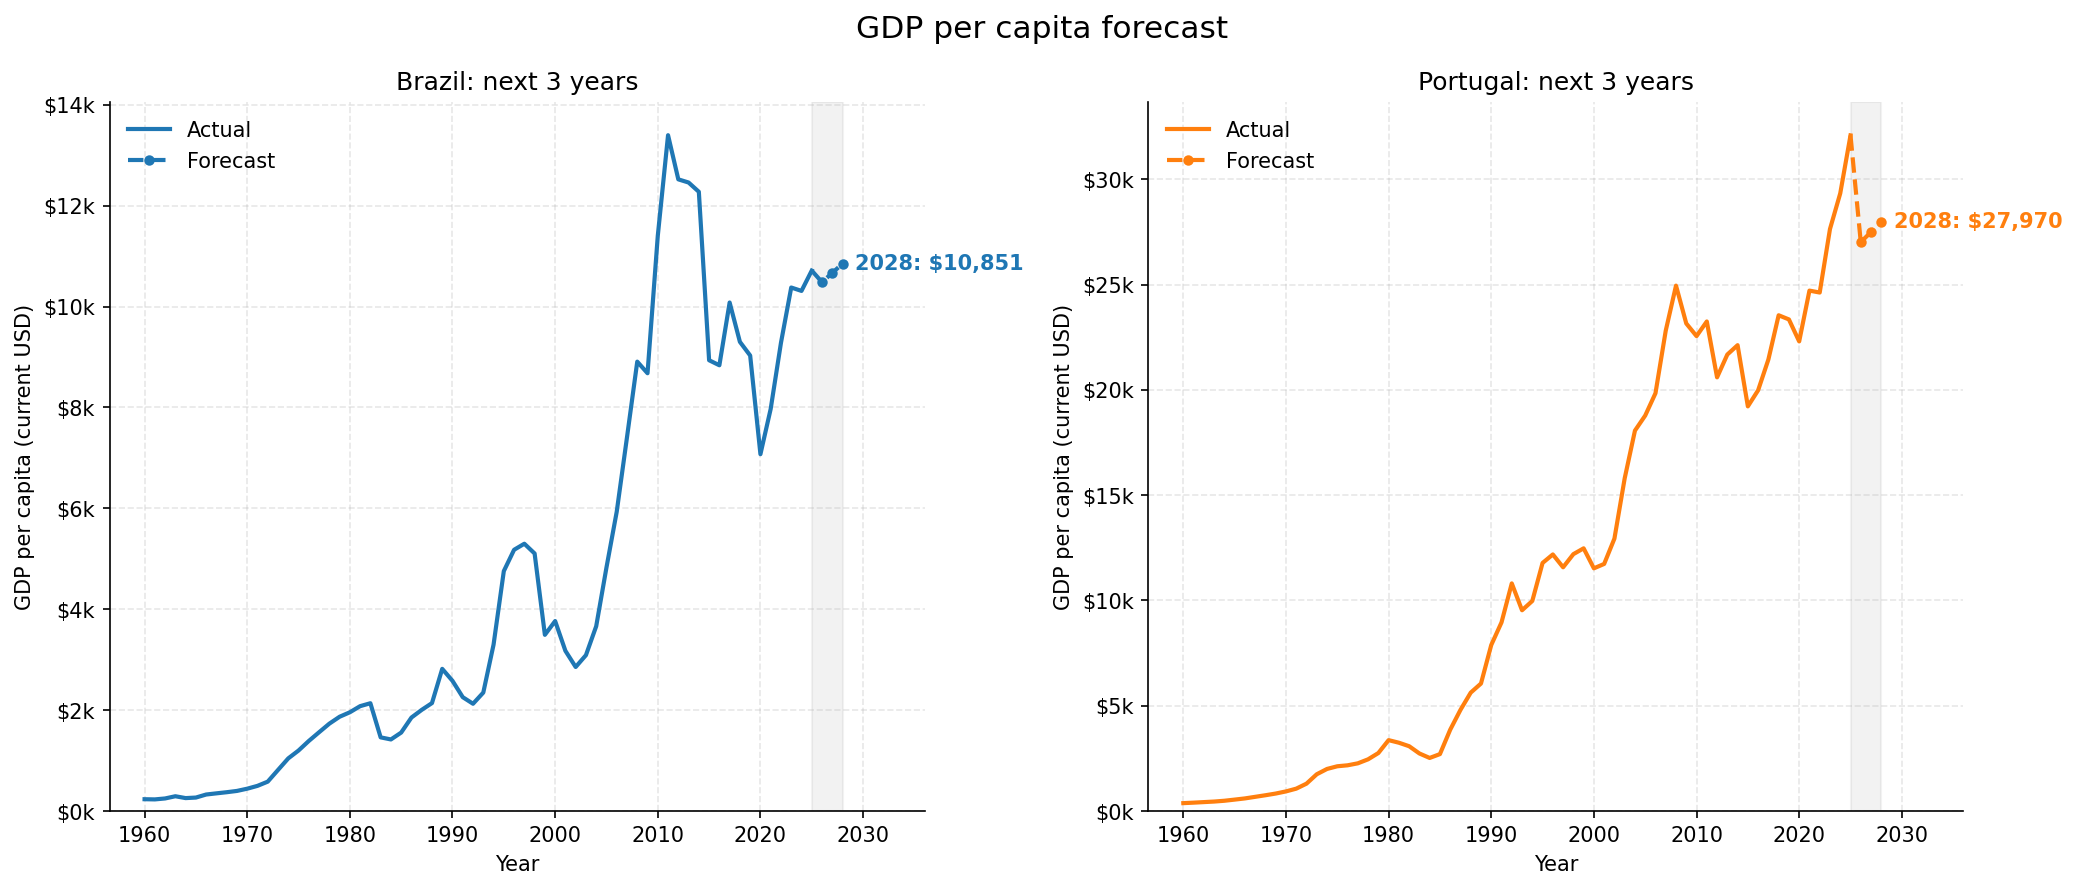

In [47]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

usd_k = FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")


def plot_forecast(ax, df, future_years, future_pred, name, color, resid_std=None):
    future_years = np.ravel(future_years)
    future_pred = np.ravel(future_pred)
    last_year = df["year"].iloc[-1]
    last_val = df["gdp_per_capita"].iloc[-1]

    # Actual series
    ax.plot(df["year"], df["gdp_per_capita"], color=color, linewidth=2, label="Actual")

    # Forecast, connected to the last actual point so there's no gap
    x_fc = np.concatenate([[last_year], future_years])
    y_fc = np.concatenate([[last_val], future_pred])
    ax.plot(
        x_fc,
        y_fc,
        color=color,
        linestyle="--",
        linewidth=2,
        marker="o",
        markersize=4,
        markevery=slice(1, None),
        label="Forecast",
    )

    # Approximate 95% band from in-sample residuals (optional)
    if resid_std is not None:
        ax.fill_between(
            future_years,
            future_pred - 1.96 * resid_std,
            future_pred + 1.96 * resid_std,
            color=color,
            alpha=0.2,
            label="~95% interval",
        )

    # Shade the forecast horizon instead of filling down to zero
    ax.axvspan(last_year, future_years[-1], color="gray", alpha=0.1, zorder=0)

    # Label the last forecast value
    ax.annotate(
        f"{future_years[-1]}: ${future_pred[-1]:,.0f}",
        xy=(future_years[-1], future_pred[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=color,
    )

    ax.yaxis.set_major_formatter(usd_k)
    ax.set_xlabel("Year")
    ax.set_ylabel("GDP per capita (current USD)")
    ax.set_title(f"{name}: next {len(future_years)} years")
    ax.set_ylim(bottom=0)
    ax.set_xlim(right=future_years[-1] + 8)  # room for the label
    ax.grid(True, alpha=0.3, linestyle="--")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left")


fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), dpi=150)

# resid_std = np.std(y_true - model.predict(X))  # per country, if you want the band
plot_forecast(
    axes[0],
    df_brazil,
    future_years,
    future_predictions_brazil,
    "Brazil",
    color="#1f77b4",
    resid_std=None,
)
plot_forecast(
    axes[1],
    df_portugal,
    future_years,
    future_predictions_portugal,
    "Portugal",
    color="#ff7f0e",
    resid_std=None,
)

fig.suptitle("GDP per capita forecast", fontsize=15)
fig.tight_layout()


save_path = (
    ROOT / "outputs_results/03_linear_regression_timeseries_forecast/gdp_forecast.png"
)
save_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(save_path, bbox_inches="tight", facecolor="white")  # after tight_layout
plt.show()